In [1]:
import pandas as pd
import numpy as np
from lm_polygraph.generation_metrics import AlignScore
import evaluate
from tqdm import tqdm

/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from transformers import AutoTokenizer

In [3]:
import os
os.environ["HF_EVALUATE_OFFLINE"]="1"

In [4]:
rouge = evaluate.load('rouge')

In [5]:
def calc_lengths(dat, tokenizer):
    def tokenize(question, context, answer):
        answer = str(answer)
        messages = [
            {"role": "user", "content": f"Question:\n{question}\nContext:\n{context}\n"},
            {"role": "assistant", "content": f"Answer:\n{answer}\n"},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=False
        )
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat["question"].loc[idx], dat["context"].loc[idx], dat["target"].loc[idx])
        lengths.append(toks)
    return lengths    

In [6]:
def calc_em_cuad(targets, preds):
    exact_match = []
    for target, pred in zip(targets, preds):
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        exact_match.append(int(str(target).strip() == str(parsed_pred).strip()))
    return exact_match

In [7]:
def calc_alignscore(targets, preds, scorer):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    scores = scorer({"greedy_texts": filtered_preds}, [str(el) for el in targets])
    return scores

In [8]:
def calc_rouge(targets, preds, rouge):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    #rouge = evaluate.load('rouge')
    results = rouge.compute(predictions=filtered_preds,
                            references=targets, use_aggregator=False)
    return results

# Recalc metrics for balanced support

## Set files

In [188]:
fnames_bal_sup = [
    
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/base_model/cnli/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_500/checkpoint-320/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_250/checkpoint-240/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_250/checkpoint-180/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_250/checkpoint-60/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_250/checkpoint-180/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_3e-05_250/checkpoint-190/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/runs/finetune/armt_sw/cnli/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_250/checkpoint-60/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_cnli/google/gemma-3-1b-it/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

]


mod_names_bal_sup = [
    "Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt",
    "Gemma3-1b-IT",
]

new_index_bal_sup = mod_names_bal_sup

In [189]:
#scorer = AlignScore(target_is_claims=True)

In [190]:
dat_bal_sup = pd.read_csv(fnames_bal_sup[0])
for idx, fname in enumerate(fnames_bal_sup[1:]):
    buf_dat = pd.read_csv(fname)
    #dat[f"output_{idx}"] = buf_dat["output"]
    dat_bal_sup[mod_names_bal_sup[idx+1]] = buf_dat["output"]
dat_bal_sup = dat_bal_sup.rename({"output": mod_names_bal_sup[0]}, axis=1)

In [191]:
dat_bal_sup

,Unnamed: 0,target,Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k,question,context,time,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt,Gemma3-1b-IT
0,0,Not mentioned,Answer:\nNot mentioned,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party shall not reverse engineer any objects which embody Disclosing Party's Confident...,0.711499,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Contradiction
1,1,Entailment,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party shall destroy or return some Confidential Information upon the termination of Ag...,0.288041,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Contradiction
2,2,Entailment,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Agreement shall not grant Receiving Party any right to Confidential Information.\n\nNON-DISCLOSU...,0.288042,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Contradiction
3,3,Not mentioned,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party shall not disclose the fact that Agreement was agreed or negotiated.\n\nNON-DISC...,0.287513,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nEntailment,Contradiction
4,4,Contradiction,Answer:\nContradiction,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Confidential Information shall only include technical information.\n\nNON-DISCLOSURE AGREEMENT\n...,0.287716,Answer:\nNot mentioned,Answer:\nContradiction,Answer:\nContradiction,Answer:\nNot mentioned,Answer:\nContradiction,Answer:\nContradiction,Contradiction
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2086,2086,Not mentioned,Answer:\nNot mentioned,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party may create a copy of some Confidential Information in some circumstances.\n\nEXE...,0.265028,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Answer:\nNot mentioned,Return only the answer.
2087,2087,Entailment,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...","Receiving Party shall notify Disclosing Party in case Receiving Party is required by law, regula...",0.306070,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Return only the answer.
2088,2088,Entailment,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party may acquire information similar to Confidential Information from a third party.\...,0.305626,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Answer:\nNot mentioned,Answer:\nEntailment,Answer:\nEntailment,Here’s the classification of the provided text:\n\nContradiction
2089,2089,Entailment,Answer:\nEntailment,"Given the following hypothesis and premise, classify it as 'Contradiction', 'Entailment' or 'Not...",Receiving Party may share some Confidential Informati

In [192]:
#dat_bal_sup["LLama3-1b-IT-all-lin-64-128-GR-4s"][0]

In [193]:
tokenizer_bal = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")

In [194]:
lens_bal_sup = calc_lengths(dat_bal_sup, tokenizer_bal)

In [195]:
dat_bal_sup["lens"] = lens_bal_sup

In [196]:
# get times
time_res = {}
for path, name in zip(fnames_bal_sup, mod_names_bal_sup):
    buf_df = pd.read_csv(path)
    if path == fnames_bal_sup[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
    time_res[f"{name}_time"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(dat_bal_sup, tokenizer_bal)

In [197]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6]#, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192]#, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [198]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k
Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k_time,0.264084,0.277619,0.282108,0.297181,0.322642
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s_time,0.231166,0.338168,0.397928,0.476589,0.617119
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s_time,0.247485,0.350884,0.435273,0.534085,0.687224
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s_time,0.257280,0.363063,0.450766,0.570438,0.693635
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt_time,0.250197,0.391750,0.443201,0.506824,0.672237
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt_time,0.216451,0.331041,0.402126,0.482277,0.645960
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt_time,0.253950,0.381956,0.470140,0.575302,0.750323
Gemma3-1b-IT_time,0.142305,0.152693,0.182817,0.316515,0.174675


In [199]:
mods_bal_sup = dat_bal_sup.columns[2:]
mods_bal_sup = [el for el in mods_bal_sup if el not in ['question', 'context', 'lens', 'time']]
scores_bal_sup = {}
scores_align_bal_sup = {}
for mod in tqdm(mods_bal_sup):
    mod_em = calc_em_cuad(dat_bal_sup["target"], dat_bal_sup[mod])
    #print(mod_em)
    #scores[mod] = mod_em
    #for key in mod_em.keys():
    #    dat_bal_sup[f"target_{mod}_{key}"] = mod_em[key]
    #mod_align = np.zeros_like(mod_em[key])#calc_alignscore(dat["target"], dat[mod], scorer)
    dat_bal_sup[f"target_{mod}_em"] = mod_em
print(scores_bal_sup)

100%|██████████| 8/8 [00:00<00:00, 752.83it/s]

{}


In [200]:
targ_cols_only_bal_sup = [el for el in dat_bal_sup.columns if (("_align" in el or "len" in el) and "_lens" not in el)]
results_alignscore_bal_sup = {}
targs_bal_sup = dat_bal_sup[targ_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [1024, 2048, 4096, 8192, 16384, 32768, 32768*2]
starts = [0, 1024, 2048, 4096, 1024*6]#, 8192]#, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192]#, 1024*10]#, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_alignscore_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [201]:
support_bal_sup = []
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    support_bal_sup.append(len(buf_res))

In [202]:
support_bal_sup

[286, 955, 629, 170, 51]

In [203]:
support_bal_sup

[286, 955, 629, 170, 51]

In [204]:
alignscores_bal_sup = pd.concat(results_alignscore_bal_sup, axis=1)
alignscores_bal_sup = alignscores_bal_sup.drop("lens")
alignscores_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k


In [205]:
targ_cols_only_bal_sup = [el for el in dat_bal_sup.columns if ((("_em" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_em_bal_sup = {}
targs_bal_sup = dat_bal_sup[targ_cols_only_bal_sup]
starts = [0, 0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [2048, 1024, 2048, 4096, 8192, 16384, 32768, 32768*2]
starts = [0, 1024, 2048, 4096, 1024*6]#, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192]#, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_em_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [206]:
ems_bal_sup = pd.concat(results_em_bal_sup, axis=1)
ems_bal_sup = ems_bal_sup.drop("lens")
ems_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k
target_Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k_em,0.702797,0.690052,0.699523,0.805882,0.921569
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s_em,0.615385,0.672251,0.511924,0.347059,0.254902
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s_em,0.678322,0.691099,0.680445,0.747059,0.764706
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s_em,0.709790,0.700524,0.729730,0.776471,0.882353
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt_em,0.688811,0.671204,0.542130,0.358824,0.254902
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt_em,0.674825,0.723560,0.702703,0.747059,0.784314
target_ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt_em,0.702797,0.737173,0.726550,0.764706,0.823529
target_Gemma3-1b-IT_em,0.426573,0.089005,0.046105,0.011765,0.196078


In [207]:
ems_bal_sup.index = new_index_bal_sup
ems_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k
Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k,0.702797,0.690052,0.699523,0.805882,0.921569
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s,0.615385,0.672251,0.511924,0.347059,0.254902
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s,0.678322,0.691099,0.680445,0.747059,0.764706
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s,0.709790,0.700524,0.729730,0.776471,0.882353
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt,0.688811,0.671204,0.542130,0.358824,0.254902
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt,0.674825,0.723560,0.702703,0.747059,0.784314
ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt,0.702797,0.737173,0.726550,0.764706,0.823529
Gemma3-1b-IT,0.426573,0.089005,0.046105,0.011765,0.196078


In [208]:
ems_bal_sup.to_csv("cnli_res_em_0k_8k.csv")

## Build initial res table

In [209]:
import copy

In [210]:
pd.set_option('display.max_colwidth', 100)
als_bal_sup = copy.deepcopy(alignscores_bal_sup)
emss_bal_sup = copy.deepcopy(ems_bal_sup)
als_bal_sup = als_bal_sup.reset_index()
als_bal_sup = als_bal_sup.rename({"index": "Model"}, axis=1)
emss_bal_sup = emss_bal_sup.reset_index()
emss_bal_sup = emss_bal_sup.rename({"index": "Model"}, axis=1)

In [211]:
emss_bal_sup

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k
0,Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k,0.702797,0.690052,0.699523,0.805882,0.921569
1,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s,0.615385,0.672251,0.511924,0.347059,0.254902
2,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s,0.678322,0.691099,0.680445,0.747059,0.764706
3,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s,0.709790,0.700524,0.729730,0.776471,0.882353
4,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt,0.688811,0.671204,0.542130,0.358824,0.254902
5,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt,0.674825,0.723560,0.702703,0.747059,0.784314
6,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt,0.702797,0.737173,0.726550,0.764706,0.823529
7,Gemma3-1b-IT,0.426573,0.089005,0.046105,0.011765,0.196078


## Build Gemma3-1b results, with mt-v2 like params, from 2s

In [212]:
buf_res = emss_bal_sup.iloc[np.arange(0, len(emss_bal_sup))].round(3)

In [213]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
#cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
#cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
#cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [214]:
#buf_res["In-Domain (0k-8k)"] = cumulative_score_id
#buf_res["OOD (8k-65k)"] = cumulative_score_ood
#buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-8k)"] = cumulative_score

In [215]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,Full (0k-8k)
0,Gemma3-1b-IT-all-lin-64-128-CNLI-mt-v2-like-8k,0.703,0.690,0.700,0.806,0.922,0.710
1,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s,0.615,0.672,0.512,0.347,0.255,0.579
2,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s,0.678,0.691,0.680,0.747,0.765,0.692
3,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s,0.710,0.701,0.730,0.776,0.882,0.721
4,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-2k-2s-from-pt,0.689,0.671,0.542,0.359,0.255,0.599
5,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-4k-4s-from-pt,0.675,0.724,0.703,0.747,0.784,0.714
6,ARMT-Gemma3-1b-IT-all-lin-64-128-CNLI-no-sw-mt-v2-like-8k-8s-from-pt,0.703,0.737,0.727,0.765,0.824,0.734
7,Gemma3-1b-IT,0.427,0.089,0.046,0.012,0.196,0.119


## Prepare paper results

### Best CNLI

In [216]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[7, 0, 1,2,3, 4,5,6]].round(3)

In [217]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
#cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
#cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
#cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [218]:
#buf_res["In-Domain (0k-8k)"] = cumulative_score_id
#buf_res["OOD (8k-65k)"] = cumulative_score_ood
#buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-8k)"] = cumulative_score

In [219]:
new_names = [
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, CNLI, 8k",
    "ARMT-Gemma-3-1B-IT, CNLI, 2k",
    "ARMT-Gemma-3-1B-IT, CNLI, 4k",
    "ARMT-Gemma-3-1B-IT, CNLI, 8k",
    "ARMT-Gemma-3-1B-IT, CNLI, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, CNLI, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, CNLI, 8k (pretrain)",
    #"Gemma-3-1B-IT, base prompt",
    #"Gemma-3-1B-IT, instructive prompt",
]
buf_res["Model"] = new_names

In [220]:
buf_res = buf_res.loc[[7,0, 1,2,3, 4,5,6]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [221]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, base prompt","Gemma-3-1B-IT, CNLI, 8k","ARMT-Gemma-3-1B-IT, CNLI, 2k","ARMT-Gemma-3-1B-IT, CNLI, 4k","ARMT-Gemma-3-1B-IT, CNLI, 8k","ARMT-Gemma-3-1B-IT, CNLI, 2k (pretrain)","ARMT-Gemma-3-1B-IT, CNLI, 4k (pretrain)","ARMT-Gemma-3-1B-IT, CNLI, 8k (pretrain)"
0k_1k,0.427,0.703,0.615,0.678,0.710,0.689,0.675,0.703
1k_2k,0.089,0.690,0.672,0.691,0.701,0.671,0.724,0.737
2k_4k,0.046,0.700,0.512,0.680,0.730,0.542,0.703,0.727
4k_6k,0.012,0.806,0.347,0.747,0.776,0.359,0.747,0.765
6k_8k,0.196,0.922,0.255,0.765,0.882,0.255,0.784,0.824
Full (0k-8k),0.119,0.710,0.579,0.692,0.721,0.599,0.714,0.734


In [222]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, base prompt & Gemma-3-1B-IT, CNLI, 8k & ARMT-Gemma-3-1B-IT, CNLI, 2k & ARMT-Gemma-3-1B-IT, CNLI, 4k & ARMT-Gemma-3-1B-IT, CNLI, 8k & ARMT-Gemma-3-1B-IT, CNLI, 2k (pretrain) & ARMT-Gemma-3-1B-IT, CNLI, 4k (pretrain) & ARMT-Gemma-3-1B-IT, CNLI, 8k (pretrain) \\
\midrule
0k-1k & {\cellcolor[HTML]{FFE800}} \color[HTML]{000000} 0.427 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.703 & {\cellcolor[HTML]{ACD600}} \color[HTML]{000000} 0.615 & {\cellcolor[HTML]{88C400}} \color[HTML]{000000} 0.678 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.710 & {\cellcolor[HTML]{82C100}} \color[HTML]{000000} 0.689 & {\cellcolor[HTML]{8AC500}} \color[HTML]{000000} 0.675 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.703 \\
1k-2k & {\cellcolor[HTML]{FF2A00}} \color[HTML]{F1F1F1} 0.089 & {\cellcolor[HTML]{82C100}} \color[HTML]{000000} 0.690 & {\cellcolor[HTML]{8CC600}} \color[HTML]{000000} 0.672 & {\cellcolor[HTML]{80C000}} \color[HTML]

### Best GR-100+, assoc. ablation, top-1 and top-4

In [207]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54]].round(3)

In [208]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [209]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [210]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
]

buf_res["Model"] = new_names

In [211]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
buf_res = buf_res.loc[[13, 12]+ [21,22,23,24] + [53,54]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [212]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used"
0k_1k,0.380,0.358,0.358,0.358,0.358,0.358,0.358,0.358
1k_2k,0.385,0.303,0.306,0.301,0.232,0.234,0.207,0.299
2k_4k,0.352,0.279,0.277,0.279,0.186,0.212,0.180,0.285
4k_6k,0.344,0.303,0.295,0.273,0.165,0.198,0.160,0.278
6k_8k,0.296,0.254,0.246,0.243,0.165,0.188,0.144,0.244
8k_10k,0.306,0.235,0.238,0.219,0.155,0.190,0.133,0.233
10k_12k,0.269,0.241,0.237,0.226,0.152,0.188,0.129,0.241
12k_14k,0.280,0.237,0.233,0.223,0.156,0.176,0.146,0.230
14k_16k,0.231,0.240,0.234,0.222,0.154,0.169,0.140,0.237
16k_24k,0.269,0.252,0.248,0.220,0.155,0.182,0.121,0.247


In [213]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{088400}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{9ECF00}} \color[HTM

## After ARR deadline

### Best GR-100+ VS RMT

In [89]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 93,95, 132,133, 167,168,169, 196,197]].round(3)

In [90]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [91]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [92]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k",

    "RMT-Gemma-3-1B-IT, GR-100+, 2k",
    "RMT-Gemma-3-1B-IT, GR-100+, 4k",
]
buf_res["Model"] = new_names

In [93]:
#buf_res = buf_res.loc[[13,10,11,12,16,17,18, 93,95]]
buf_res = buf_res.loc[[13,10,11,12, 196, 197]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [94]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","RMT-Gemma-3-1B-IT, GR-100+, 2k","RMT-Gemma-3-1B-IT, GR-100+, 4k"
0k_1k,0.380,0.357,0.357,0.358,0.218,0.242
1k_2k,0.385,0.296,0.294,0.303,0.198,0.224
2k_4k,0.352,0.264,0.275,0.279,0.132,0.168
4k_6k,0.344,0.240,0.286,0.303,0.138,0.170
6k_8k,0.296,0.219,0.238,0.254,0.122,0.165
8k_10k,0.306,0.205,0.233,0.235,0.104,0.152
10k_12k,0.269,0.213,0.221,0.241,0.119,0.157
12k_14k,0.280,0.193,0.225,0.237,0.119,0.127
14k_16k,0.231,0.180,0.217,0.240,0.114,0.117
16k_24k,0.269,0.115,0.200,0.252,0.106,0.103


In [97]:
print(buf_res.to_markdown(floatfmt=".3f").replace("  ", ""))

|| Gemma-3-1B-IT, GR-100+, 8k | ARMT-Gemma-3-1B-IT, GR-100+, 2k | ARMT-Gemma-3-1B-IT, GR-100+, 4k | ARMT-Gemma-3-1B-IT, GR-100+, 8k | RMT-Gemma-3-1B-IT, GR-100+, 2k | RMT-Gemma-3-1B-IT, GR-100+, 4k |
|:-------------------|-----------------------------:|----------------------------------:|----------------------------------:|----------------------------------:|---------------------------------:|---------------------------------:|
| 0k_1k|0.380 | 0.357 | 0.357 | 0.358 |0.218 |0.242 |
| 1k_2k|0.385 | 0.296 | 0.294 | 0.303 |0.198 |0.224 |
| 2k_4k|0.352 | 0.264 | 0.275 | 0.279 |0.132 |0.168 |
| 4k_6k|0.344 | 0.240 | 0.286 | 0.303 |0.138 |0.170 |
| 6k_8k|0.296 | 0.219 | 0.238 | 0.254 |0.122 |0.165 |
| 8k_10k |0.306 | 0.205 | 0.233 | 0.235 |0.104 |0.152 |
| 10k_12k|0.269 | 0.213 | 0.221 | 0.241 |0.119 |0.157 |
| 12k_14k|0.280 | 0.193 | 0.225 | 0.237 |0.119 |0.127 |
| 14k_16k|0.231 | 0.180 | 0.217 | 0.240 |0.114 |0.117 |
| 16k_24k|0.269 | 0.115 | 0.200 | 0.252 |0.106 |0.103 |
| 24k_32k|0.247 | 

In [80]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & RMT-Gemma-3-1B-IT, GR-100+, 2k & RMT-Gemma-3-1B-IT, GR-100+, 4k \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{DEEF00}} \color[HTML]{000000} 0.218 & {\cellcolor[HTML]{BEDF00}} \color[HTML]{000000} 0.242 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.294 & {\cellcolor[HTML]{6CB600}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{F8FC00}} \color[HTML]{000000} 0.198 & {\cellcolor[HTML]{D6EB00}} \color[HTML]{000000} 0.224 \\
2k-4k & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.352

## Figures for ICLR poster

### Best GR-100+, main results, for plot

In [54]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77, 132,133, 135]].round(3)

In [55]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [56]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [57]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "Mamba-train-64",
]

buf_res["Model"] = new_names

In [58]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[13, 10,11,12] + [53,54] + [62,  77, 132,133, 135]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [59]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",Mamba-train-64
0k_1k,0.380,0.357,0.357,0.358,0.358,0.358,0.347,0.363,0.370,0.382,0.320
1k_2k,0.385,0.296,0.294,0.303,0.207,0.299,0.291,0.317,0.316,0.295,0.329
2k_4k,0.352,0.264,0.275,0.279,0.180,0.285,0.265,0.304,0.293,0.302,0.304
4k_6k,0.344,0.240,0.286,0.303,0.160,0.278,0.262,0.287,0.303,0.315,0.281
6k_8k,0.296,0.219,0.238,0.254,0.144,0.244,0.241,0.250,0.260,0.261,0.278
8k_10k,0.306,0.205,0.233,0.235,0.133,0.233,0.232,0.231,0.245,0.238,0.266
10k_12k,0.269,0.213,0.221,0.241,0.129,0.241,0.232,0.231,0.260,0.260,0.235
12k_14k,0.280,0.193,0.225,0.237,0.146,0.230,0.222,0.221,0.252,0.251,0.253
14k_16k,0.231,0.180,0.217,0.240,0.140,0.237,0.233,0.243,0.262,0.244,0.248
16k_24k,0.269,0.115,0.200,0.252,0.121,0.247,0.242,0.259,0.260,0.273,0.260


In [60]:
import matplotlib.pyplot as plt
import matplotlib as mpl


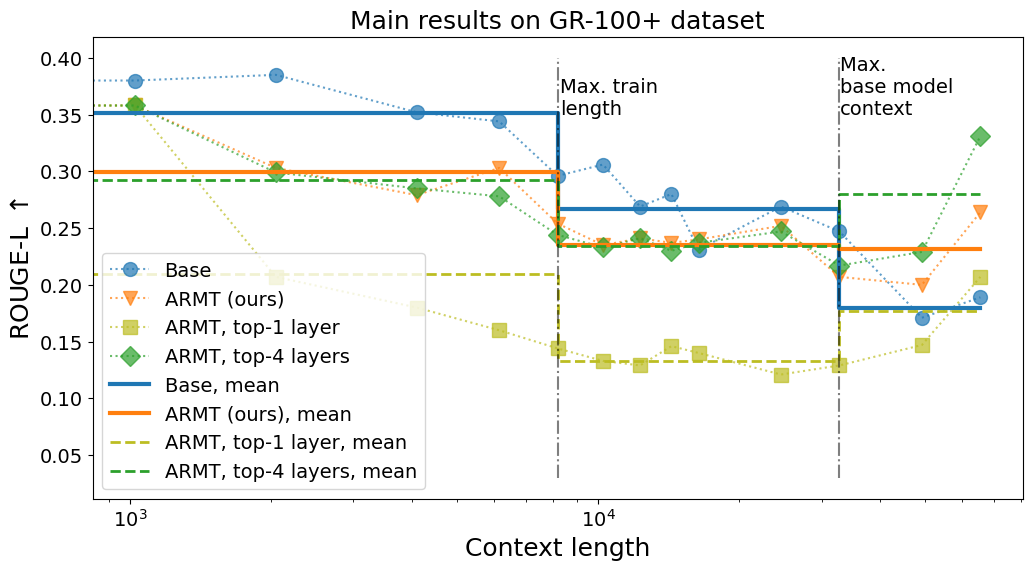

In [62]:

model_keys = [
    "Gemma-3-1B-IT, GR-100+, 8k",
    #"Mamba-train-64",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    #"ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    #"ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
]
model_names = [
    "Base",
    #"Mamba",
    "ARMT (ours)",
    "ARMT, top-1 layer",
    "ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    #"ARMT, pre-selected layers, \ntrained (ours)",
    #"ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(12,6))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,8, 2, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.36] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("ROUGE-L $\\uparrow$", fontsize=global_fs)
plt.title("Main results on GR-100+ dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/poster_iclr_main_res_gr100_plus_gemma_small.pdf")

## Subset for Loss eval for pt model

In [50]:
# load and save subset of fineweb-edu for loss evals
from datasets import load_dataset
dataset = load_dataset('HuggingFaceFW/fineweb-edu', split='train', streaming=True)
data_subset = []
for idx in tqdm(range(1000)):
    data_subset.append(next(iter(dataset)))
    #print(next(iter(dataset)))

100%|██████████| 1000/1000 [15:09<00:00,  1.10it/s]


In [52]:
import datasets

In [53]:
fineweb_subset = datasets.Dataset.from_list(data_subset)

In [54]:
eval_data = datasets.DatasetDict(
    {"train": fineweb_subset,
     "validation": fineweb_subset,
     "test": fineweb_subset}
)

In [55]:
eval_data.save_to_disk("../../data/fineweb_train_subset")

Saving the dataset (1/1 shards): 100%|██████████| 1000/1000 [00:00<00:00, 87226.87 examples/s]


In [56]:
dataset = load_dataset('karpathy/fineweb-edu-100b-shuffle', split='train', streaming=True)
data_subset = []
for idx in tqdm(range(1000)):
    data_subset.append(next(iter(dataset)))
    #print(next(iter(dataset)))

100%|██████████| 1000/1000 [10:45<00:00,  1.55it/s]


In [57]:
fineweb_subset = datasets.Dataset.from_list(data_subset)
eval_data = datasets.DatasetDict(
    {"train": fineweb_subset,
     "validation": fineweb_subset,
     "test": fineweb_subset}
)

In [58]:
eval_data.save_to_disk("../../data/fineweb_train_subset_karp")

Saving the dataset (1/1 shards): 100%|██████████| 1000/1000 [00:00<00:00, 52851.61 examples/s]


# Calculate data stats

In [ ]:
import datasets
data_pathes = [
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/",
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/",
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/",
    "../../data/gov_report/gov_report_0k_2k/",
    "../../data/gov_report/gov_report_0k_4k/",
    "../../data/gov_report/gov_report_0k_8k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_2k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_4k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_8k/",
]

In [491]:
for dpath in data_pathes:
    ds = datasets.load_from_disk(dpath)
    print(dpath)
    print(f"{np.round(len(ds['train']) / 1000, 1)}k & ", f"{np.round(len(ds['validation']) / 1000, 1)}k & ", f"{np.round(len(ds['test']) / 1000, 1)}k & ", np.mean(ds["train"]["length"]))

../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/
229.4k &  3.1k &  23.6k &  1172.5093511508605
../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/
289.2k &  4.5k &  32.0k &  2191.8969485313187
../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/
328.3k &  5.1k &  34.7k &  3940.205497521759
../../data/gov_report/gov_report_0k_2k/
9.9k &  0.5k &  1.3k &  1557.8849843481773
../../data/gov_report/gov_report_0k_4k/
17.4k &  0.9k &  2.2k &  2839.9674498567333
../../data/gov_report/gov_report_0k_8k/
19.7k &  1.0k &  2.5k &  4781.661873793314
../../data/gov_report_100_gen_plus/gov_report_0k_2k/
90.5k &  0.5k &  1.3k &  1427.9492351562844
../../data/gov_report_100_gen_plus/gov_report_0k_4k/
121.7k &  0.9k &  2.2k &  2581.5798997452544
../../data/gov_report_100_gen_plus/gov_report_0k_8k/
128.4k &  1.0k &  2.5k &  4438.172931979569


# Extract examples

In [169]:
import datasets

In [170]:
ds = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/")

In [198]:
short_ids = np.argsort(ds["train"]["length"])#[:1000]

In [211]:
idx = 5523
for key in ds["train"][0].keys():
    print(key)
    if key == "context":
        print(ds["train"][int(short_ids[idx])][key].replace("\n", "\\newline ").replace("_", "\_"))
    else:
        print(ds["train"][int(short_ids[idx])][key])

repo_name
viaict/viaduct
fname
['repos/viaict/viaduct/migrations/versions/2018_09_05_6aff43ad8f2a_change_company_description_to_text.py']
context
from typing import Any \newline import typing \newline [docstring] \newline from alembic import op \newline import sqlalchemy as sa \newline \newline \newline from sqlalchemy . ext . declarative import declarative\_base \newline from sqlalchemy . orm import sessionmaker , relationship \newline \newline [comment] \newline revision = [string] \newline down\_revision = [string] \newline \newline Base = declarative\_base ( ) \newline db = sa \newline db . Model = Base \newline db . relationship = relationship \newline \newline \newline def create\_session ( ) : \newline connection = op . get\_bind ( ) \newline session\_maker = sa . orm . sessionmaker ( ) \newline session = session\_maker ( bind = connection ) \newline db . session = session \newline \newline \newline def upgrade ( ) : \newline create\_session ( ) \newline \newline [comment] \newl

In [212]:
ds = datasets.load_from_disk("../../data/gov_report/gov_report_0k_2k/")

In [213]:
short_ids = np.argsort(ds["train"]["length"])#[:1000]

In [225]:
idx = 12 #2
for key in ds["train"][0].keys():
    print(key)
    if key == "context":
        #print(ds["train"][int(short_ids[idx])][key])
        print(ds["train"][int(short_ids[idx])][key].replace("\n", "\\newline ").replace("_", "\_"))
    else:
        print(ds["train"][int(short_ids[idx])][key])

doc_id
GAO_GAO-13-762T
context
Economic Significance of Intellectual Property Protection and Theft\newline As we reported in April 2010, IP is an important component of the U.S. economy and IP-related industries pay higher wages and contribute a significant percentage to the U.S. economy. However, the U.S. economy as a whole may grow at a slower pace than it otherwise would because of counterfeiting and piracy’s effect on U.S. industries, government, and consumers.\newline Quantifying Economic Impacts Is Difficult, However Industry Research Suggests the Impacts Are Sizable\newline Generally, as we reported in April 2010, the illicit nature of counterfeiting and piracy makes estimating the economic impact of IP infringements extremely difficult, so assumptions must be used to offset the lack of data. Efforts to estimate losses involve assumptions such as the rate at which consumers would substitute counterfeit for legitimate products, which can have enormous impacts on the resulting est

In [242]:
import datasets

In [243]:
mt_v2_bal_sup = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_v2_bal_support")

In [245]:
mt_v2_bal_sup.push_to_hub("AIRI-NLP/test_mt_v2_0k_64k_balnced_support", private=True, token="")

Creating parquet from Arrow format: 100%|██████████| 2/2 [00:00<00:00, 14.64ba/s]
Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.
Uploading the dataset shards: 100%|██████████| 1/1 [00:02<00:00,  2.09s/it]


CommitInfo(commit_url='https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_64k_balnced_support/commit/acf6e155ac8bf852f2c5736b311383877736ca40', commit_message='Upload dataset', commit_description='', oid='acf6e155ac8bf852f2c5736b311383877736ca40', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_64k_balnced_support', endpoint='https://huggingface.co', repo_type='dataset', repo_id='AIRI-NLP/test_mt_v2_0k_64k_balnced_support'), pr_revision=None, pr_num=None)

In [246]:
gov_rep_bal_sup = datasets.load_from_disk("../../data/gov_report/gov_report_0k_64k_test_only_bal_support")

In [247]:
gov_rep_bal_sup.push_to_hub("AIRI-NLP/test_gov_rep_0k_64k_balanced_support", private=True, token="")

Creating parquet from Arrow format: 100%|██████████| 2/2 [00:00<00:00, 17.47ba/s]
Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.
Uploading the dataset shards: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it]


CommitInfo(commit_url='https://huggingface.co/datasets/AIRI-NLP/test_gov_rep_0k_64k_balanced_support/commit/4ff47f75d391ff745529c5a0384cf9dc24e0cbd1', commit_message='Upload dataset', commit_description='', oid='4ff47f75d391ff745529c5a0384cf9dc24e0cbd1', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/AIRI-NLP/test_gov_rep_0k_64k_balanced_support', endpoint='https://huggingface.co', repo_type='dataset', repo_id='AIRI-NLP/test_gov_rep_0k_64k_balanced_support'), pr_revision=None, pr_num=None)